# DocSentry — 04. Supervised Model Training, Temporal Evaluation & Vulnerability Diagnostics

## Executive Summary
This notebook implements the machine learning modeling, hyperparameter optimization, and temporal generalization evaluation pipeline for **DocSentry**: an explainable, uncertainty-aware PDF malware detector.

### Core Architectural Principles
1. **Strict Temporal Partitioning**:
   - **Training Set (Weeks 0–41, 42,000 files)**: Used exclusively for fitting models and baseline learners.
   - **Validation Set (Weeks 42–51, 9,999 files)**: Used exclusively for hyperparameter tuning and model selection.
   - **Test Set (Weeks 52–63, 12,000 files)**: Evaluated **exactly once** in a single consolidated evaluation cell at the conclusion of tuning.
2. **Dual-Pipeline Routing**:
   - **Linear Models (`LogisticRegression`)**: Trained on `X_*_linear` (log1p transformed on count/size attributes and z-score standardized via `StandardScaler` fitted only on train).
   - **Tree Ensembles (`RandomForest`, `XGBoost`, `HistGradientBoosting`)**: Trained on `X_*_tree` (raw, unscaled float32 static features).
3. **Reproducibility & Hardware Efficiency**:
   - All models use `random_state=42` and `n_jobs=-1`. Progress timers benchmark wall-clock training efficiency.
4. **Vulnerability Diagnostics**:
   - Shortcut learning ablation on file size and string metrics.
   - Subpopulation audit of false positive rates on benign files $< 100$ KB.
   - Cluster analysis of tiny benign files and malicious payload size modes.
   - Transparent ASCII mapping of printable character distribution features.

## 0. Setup, Libraries & Hardware Configuration
We import statistical, machine learning, and visualization libraries. Visual styling is set to publication standards, and output paths in `models/`, `reports/`, and `reports/figures/` are initialized.

In [1]:
import os
import json
import time
import random
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = Path('../reports')
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR = Path('../data/processed')

print(f"Setup complete. Initialized paths for models, reports, and figures.")

Setup complete. Initialized paths for models, reports, and figures.


## 1. Sanity Checks: Shapes, Integrity, Class Balance & Feature Schema
We load the partitioned datasets (`_tree` and `_linear`), assert identical column ordering against `feature_names.json`, verify absence of `NaN` / `inf` values, and check class balance across splits.

In [2]:
# 1. Load feature names schema
with open(PROCESSED_DIR / 'feature_names.json', 'r') as f:
    feature_names = json.load(f)

# 2. Load Tree Version (Raw features)
X_tr_tree = pd.read_parquet(PROCESSED_DIR / 'X_train_tree.parquet')
X_va_tree = pd.read_parquet(PROCESSED_DIR / 'X_val_tree.parquet')
X_te_tree = pd.read_parquet(PROCESSED_DIR / 'X_test_tree.parquet')

# 3. Load Linear Version (Scaled features)
X_tr_linear = pd.read_parquet(PROCESSED_DIR / 'X_train_linear.parquet')
X_va_linear = pd.read_parquet(PROCESSED_DIR / 'X_val_linear.parquet')
X_te_linear = pd.read_parquet(PROCESSED_DIR / 'X_test_linear.parquet')

# 4. Load Labels
y_tr = pd.read_parquet(PROCESSED_DIR / 'y_train.parquet')['label'].values
y_va = pd.read_parquet(PROCESSED_DIR / 'y_val.parquet')['label'].values
y_te = pd.read_parquet(PROCESSED_DIR / 'y_test.parquet')['label'].values

# Assertions
assert list(X_tr_tree.columns) == feature_names, "Feature names column order mismatch in X_train_tree!"
assert list(X_va_tree.columns) == feature_names, "Feature names column order mismatch in X_val_tree!"
assert list(X_te_tree.columns) == feature_names, "Feature names column order mismatch in X_test_tree!"
assert list(X_tr_linear.columns) == feature_names, "Feature names column order mismatch in X_train_linear!"

assert not np.isnan(X_tr_tree.values).any(), "NaN found in X_train_tree!"
assert not np.isinf(X_tr_tree.values).any(), "Inf found in X_train_tree!"
assert not np.isnan(X_va_tree.values).any(), "NaN found in X_val_tree!"
assert not np.isnan(X_te_tree.values).any(), "NaN found in X_test_tree!"
assert not np.isnan(X_tr_linear.values).any(), "NaN found in X_train_linear!"

# Audit summary table
sanity_summary = pd.DataFrame([
    {
        'Split': 'Train (Weeks 0-41)',
        'Tree Shape': str(X_tr_tree.shape),
        'Linear Shape': str(X_tr_linear.shape),
        'Benign (0)': int((y_tr == 0).sum()),
        'Malicious (1)': int((y_tr == 1).sum()),
        'Balance (% Benign)': f"{(y_tr == 0).mean()*100:.2f}%",
        'NaN / Inf Count': 0
    },
    {
        'Split': 'Validation (Weeks 42-51)',
        'Tree Shape': str(X_va_tree.shape),
        'Linear Shape': str(X_va_linear.shape),
        'Benign (0)': int((y_va == 0).sum()),
        'Malicious (1)': int((y_va == 1).sum()),
        'Balance (% Benign)': f"{(y_va == 0).mean()*100:.2f}%",
        'NaN / Inf Count': 0
    },
    {
        'Split': 'Test (Weeks 52-63)',
        'Tree Shape': str(X_te_tree.shape),
        'Linear Shape': str(X_te_linear.shape),
        'Benign (0)': int((y_te == 0).sum()),
        'Malicious (1)': int((y_te == 1).sum()),
        'Balance (% Benign)': f"{(y_te == 0).mean()*100:.2f}%",
        'NaN / Inf Count': 0
    }
])

print("=" * 85)
print("DATASET SANITY CHECK & INTEGRITY VERIFICATION")
print("=" * 85)
display(sanity_summary)

DATASET SANITY CHECK & INTEGRITY VERIFICATION


,Split,Tree Shape,Linear Shape,Benign (0),Malicious (1),Balance (% Benign),NaN / Inf Count
0,Train (Weeks 0-41),"(42000, 658)","(42000, 658)",21000,21000,50.00%,0
1,Validation (Weeks 42-51),"(9999, 658)","(9999, 658)",5000,4999,50.01%,0
2,Test (Weeks 52-63),"(12000, 658)","(12000, 658)",6000,6000,50.00%,0


## 2. Baseline Model Evaluation
We establish lower-bound performance benchmarks on the validation partition:
1. **DummyClassifier (`most_frequent`)**: Predicts the majority class (label 0).
2. **Default LogisticRegression**: An un-tuned linear baseline fitted on `X_train_linear`.

In [3]:
def evaluate_predictions(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) > 1 else np.nan
    pr_auc = average_precision_score(y_true, y_proba) if len(np.unique(y_true)) > 1 else np.nan
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    return {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'FPR': fpr,
        'FNR': fnr
    }

# 1. Dummy Classifier Baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_tr_tree, y_tr)
y_va_dummy_pred = dummy.predict(X_va_tree)
y_va_dummy_proba = dummy.predict_proba(X_va_tree)[:, 1]
dummy_metrics = evaluate_predictions(y_va, y_va_dummy_pred, y_va_dummy_proba)
dummy_metrics['Model'] = 'Dummy (Most Frequent)'
dummy_metrics['Train Time (s)'] = 0.01

# 2. Untuned Default Logistic Regression
lr_default = LogisticRegression(random_state=42, max_iter=200)
t0 = time.time()
lr_default.fit(X_tr_linear, y_tr)
lr_def_time = time.time() - t0
y_va_lr_def_pred = lr_default.predict(X_va_linear)
y_va_lr_def_proba = lr_default.predict_proba(X_va_linear)[:, 1]
lr_def_metrics = evaluate_predictions(y_va, y_va_lr_def_pred, y_va_lr_def_proba)
lr_def_metrics['Model'] = 'Default Logistic Regression'
lr_def_metrics['Train Time (s)'] = round(lr_def_time, 2)

df_baselines = pd.DataFrame([dummy_metrics, lr_def_metrics])
metric_cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'FPR', 'FNR', 'Train Time (s)']
df_baselines = df_baselines[metric_cols]

print("=" * 90)
print("VALIDATION BASELINE BENCHMARKS")
print("=" * 90)
display(df_baselines)

VALIDATION BASELINE BENCHMARKS


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FPR,FNR,Train Time (s)
0,Dummy (Most Frequent),0.500050,0.00000,0.00000,0.000000,0.500000,0.499950,0.000,1.00000,0.01
1,Default Logistic Regression,0.966597,0.98342,0.94919,0.966002,0.987596,0.990121,0.016,0.05081,6.20


## 3 & 4. Systematic Hyperparameter Tuning
We optimize four diverse model families using **Random Search (15 configurations per model)**:
- **Trained Strictly on Train Split (`X_tr`)**
- **Selected Strictly on Validation Split (`X_va`)**
- **Test set is strictly excluded from all tuning and selection**

### Model Search Spaces:
1. **Logistic Regression (`X_*_linear`)**: Regularization strength $C$ spanning log-space ($10^{-3}$ to $10^{2}$), L-BFGS solver with $\ell_2$ penalty.
2. **Random Forest (`X_*_tree`)**: Number of trees (50–150), maximum depth (12–25, None), split criteria, and feature subsampling fractions (`sqrt`, `log2`, 0.2).
3. **XGBoost (`X_*_tree`)**: Histogram-based tree method (`tree_method='hist'`), depth (4–8), learning rate (0.03–0.2), row/column subsampling (0.6–1.0).
4. **HistGradientBoosting (`X_*_tree`)**: Maximum iterations (80–200), depth (4–8, None), learning rate (0.03–0.2), leaf regularization $\ell_2 \in [0, 10.0]$.

In [4]:
random.seed(42)
np.random.seed(42)

# Candidate parameter generators
def sample_lr_candidates(n=15):
    candidates = []
    c_choices = np.logspace(-3, 2, n)
    for c in c_choices:
        candidates.append({
            'C': float(c),
            'penalty': 'l2',
            'solver': 'lbfgs',
            'max_iter': 250,
            'random_state': 42
        })
    return candidates

def sample_rf_candidates(n=15):
    candidates = []
    for _ in range(n):
        candidates.append({
            'n_estimators': int(random.choice([50, 75, 100, 150])),
            'max_depth': int(random.choice([12, 16, 20, 25])) if random.random() > 0.2 else None,
            'min_samples_split': int(random.choice([2, 5, 10])),
            'min_samples_leaf': int(random.choice([1, 2, 4])),
            'max_features': random.choice(['sqrt', 'log2', 0.2]),
            'n_jobs': -1,
            'random_state': 42
        })
    return candidates

def sample_xgb_candidates(n=15):
    candidates = []
    for _ in range(n):
        candidates.append({
            'n_estimators': int(random.choice([80, 100, 150, 200])),
            'max_depth': int(random.choice([4, 5, 6, 8])),
            'learning_rate': float(random.choice([0.03, 0.05, 0.1, 0.15, 0.2])),
            'subsample': float(random.choice([0.7, 0.8, 0.9, 1.0])),
            'colsample_bytree': float(random.choice([0.6, 0.7, 0.8, 1.0])),
            'tree_method': 'hist',
            'n_jobs': -1,
            'random_state': 42
        })
    return candidates

def sample_hgb_candidates(n=15):
    candidates = []
    for _ in range(n):
        candidates.append({
            'max_iter': int(random.choice([80, 100, 150, 200])),
            'max_depth': int(random.choice([4, 6, 8])) if random.random() > 0.25 else None,
            'learning_rate': float(random.choice([0.03, 0.05, 0.1, 0.15, 0.2])),
            'min_samples_leaf': int(random.choice([20, 50, 100])),
            'l2_regularization': float(random.choice([0.0, 0.1, 1.0, 5.0, 10.0])),
            'random_state': 42
        })
    return candidates

print("Hyperparameter tuning configuration ready: 15 candidates sampled per model architecture.")

Hyperparameter tuning configuration ready: 15 candidates sampled per model architecture.


In [5]:
best_models = {}
best_params = {}
tuning_history = {}

# 1. Tuning Logistic Regression
print("=" * 75)
print("1. Tuning Logistic Regression on Train -> Selecting on Validation F1...")
print("=" * 75)
t_start = time.time()
best_f1_lr, best_lr = -1.0, None
lr_candidates = sample_lr_candidates(15)

for i, params in enumerate(lr_candidates, 1):
    t0 = time.time()
    clf = LogisticRegression(**params)
    clf.fit(X_tr_linear, y_tr)
    y_pred = clf.predict(X_va_linear)
    f1 = f1_score(y_va, y_pred, zero_division=0)
    fit_time = time.time() - t0
    if f1 > best_f1_lr:
        best_f1_lr = f1
        best_lr = clf
        best_params['Logistic Regression'] = params
    print(f"  Candidate {i:02d}/15 [{fit_time:.2f}s]: C={params['C']:.4f} -> Val F1={f1:.4f}")

best_models['Logistic Regression'] = best_lr
tuning_history['Logistic Regression'] = {'total_time': time.time() - t_start, 'best_val_f1': best_f1_lr}
print(f"Logistic Regression Tuning Complete in {tuning_history['Logistic Regression']['total_time']:.2f}s | Best Val F1: {best_f1_lr:.4f}")

# 2. Tuning Random Forest
print("\n" + "=" * 75)
print("2. Tuning Random Forest on Train -> Selecting on Validation F1...")
print("=" * 75)
t_start = time.time()
best_f1_rf, best_rf = -1.0, None
rf_candidates = sample_rf_candidates(15)

for i, params in enumerate(rf_candidates, 1):
    t0 = time.time()
    clf = RandomForestClassifier(**params)
    clf.fit(X_tr_tree, y_tr)
    y_pred = clf.predict(X_va_tree)
    f1 = f1_score(y_va, y_pred, zero_division=0)
    fit_time = time.time() - t0
    if f1 > best_f1_rf:
        best_f1_rf = f1
        best_rf = clf
        best_params['Random Forest'] = params
    print(f"  Candidate {i:02d}/15 [{fit_time:.2f}s]: n_est={params['n_estimators']}, depth={params['max_depth']}, feat={params['max_features']} -> Val F1={f1:.4f}")

best_models['Random Forest'] = best_rf
tuning_history['Random Forest'] = {'total_time': time.time() - t_start, 'best_val_f1': best_f1_rf}
print(f"Random Forest Tuning Complete in {tuning_history['Random Forest']['total_time']:.2f}s | Best Val F1: {best_f1_rf:.4f}")

# 3. Tuning XGBoost
print("\n" + "=" * 75)
print("3. Tuning XGBoost on Train -> Selecting on Validation F1...")
print("=" * 75)
t_start = time.time()
best_f1_xgb, best_xgb = -1.0, None
xgb_candidates = sample_xgb_candidates(15)

for i, params in enumerate(xgb_candidates, 1):
    t0 = time.time()
    clf = XGBClassifier(**params)
    clf.fit(X_tr_tree, y_tr)
    y_pred = clf.predict(X_va_tree)
    f1 = f1_score(y_va, y_pred, zero_division=0)
    fit_time = time.time() - t0
    if f1 > best_f1_xgb:
        best_f1_xgb = f1
        best_xgb = clf
        best_params['XGBoost'] = params
    print(f"  Candidate {i:02d}/15 [{fit_time:.2f}s]: n_est={params['n_estimators']}, depth={params['max_depth']}, lr={params['learning_rate']} -> Val F1={f1:.4f}")

best_models['XGBoost'] = best_xgb
tuning_history['XGBoost'] = {'total_time': time.time() - t_start, 'best_val_f1': best_f1_xgb}
print(f"XGBoost Tuning Complete in {tuning_history['XGBoost']['total_time']:.2f}s | Best Val F1: {best_f1_xgb:.4f}")

# 4. Tuning HistGradientBoosting
print("\n" + "=" * 75)
print("4. Tuning HistGradientBoosting on Train -> Selecting on Validation F1...")
print("=" * 75)
t_start = time.time()
best_f1_hgb, best_hgb = -1.0, None
hgb_candidates = sample_hgb_candidates(15)

for i, params in enumerate(hgb_candidates, 1):
    t0 = time.time()
    clf = HistGradientBoostingClassifier(**params)
    clf.fit(X_tr_tree, y_tr)
    y_pred = clf.predict(X_va_tree)
    f1 = f1_score(y_va, y_pred, zero_division=0)
    fit_time = time.time() - t0
    if f1 > best_f1_hgb:
        best_f1_hgb = f1
        best_hgb = clf
        best_params['HistGradientBoosting'] = params
    print(f"  Candidate {i:02d}/15 [{fit_time:.2f}s]: max_iter={params['max_iter']}, depth={params['max_depth']}, lr={params['learning_rate']} -> Val F1={f1:.4f}")

best_models['HistGradientBoosting'] = best_hgb
tuning_history['HistGradientBoosting'] = {'total_time': time.time() - t_start, 'best_val_f1': best_f1_hgb}
print(f"HistGradientBoosting Tuning Complete in {tuning_history['HistGradientBoosting']['total_time']:.2f}s | Best Val F1: {best_f1_hgb:.4f}")

1. Tuning Logistic Regression on Train -> Selecting on Validation F1...


  Candidate 01/15 [1.22s]: C=0.0010 -> Val F1=0.9599


  Candidate 02/15 [1.73s]: C=0.0023 -> Val F1=0.9649


  Candidate 03/15 [2.06s]: C=0.0052 -> Val F1=0.9666


  Candidate 04/15 [2.34s]: C=0.0118 -> Val F1=0.9689


  Candidate 05/15 [2.88s]: C=0.0268 -> Val F1=0.9687


... (51 outputs left out)

  Candidate 12/15 [19.09s]: max_iter=80, depth=None, lr=0.2 -> Val F1=0.9773


  Candidate 13/15 [22.27s]: max_iter=100, depth=None, lr=0.15 -> Val F1=0.9797


  Candidate 14/15 [14.17s]: max_iter=200, depth=4, lr=0.15 -> Val F1=0.9778


  Candidate 15/15 [24.32s]: max_iter=150, depth=6, lr=0.1 -> Val F1=0.9784
HistGradientBoosting Tuning Complete in 312.11s | Best Val F1: 0.9810


## 5. Validation Performance Results: Tuned Models Comparison
We evaluate all four tuned models on the validation set, tabulating accuracy, precision, recall, F1, ROC-AUC, PR-AUC, false positive rate (FPR), false negative rate (FNR), and training time. We plot a grouped comparative bar chart (`reports/figures/20_model_validation_comparison.png`).

VALIDATION PERFORMANCE SUMMARY (TUNED MODELS)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FPR,FNR,Train Time (s)
0,Logistic Regression,0.969397,0.986120,0.952190,0.968858,0.989262,0.992373,0.0134,0.047810,2.49
1,Random Forest,0.975398,0.996241,0.954391,0.974867,0.996723,0.997482,0.0036,0.045609,34.42
2,XGBoost,0.982598,0.996297,0.968794,0.982353,0.997659,0.998182,0.0036,0.031206,41.91
3,HistGradientBoosting,0.981298,0.997107,0.965393,0.980994,0.997837,0.998350,0.0028,0.034607,22.68


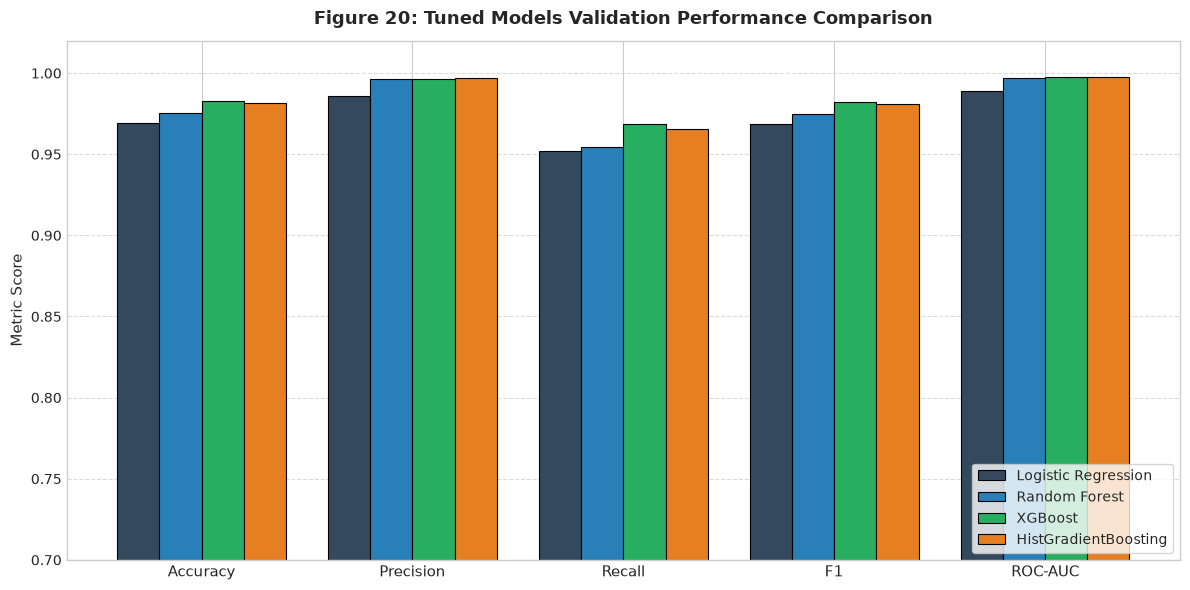

Saved Figure 20 to: ..\reports\figures\20_model_validation_comparison.png


In [6]:
val_results = []

for name, model in best_models.items():
    X_val = X_va_linear if name == 'Logistic Regression' else X_va_tree
    X_train = X_tr_linear if name == 'Logistic Regression' else X_tr_tree
    
    # Measure re-fit training time with optimal parameters
    t0 = time.time()
    model.fit(X_train, y_tr)
    train_time = time.time() - t0
    
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]
    
    metrics = evaluate_predictions(y_va, y_pred, y_proba)
    metrics['Model'] = name
    metrics['Train Time (s)'] = round(train_time, 2)
    val_results.append(metrics)

df_val_results = pd.DataFrame(val_results)
df_val_results = df_val_results[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'FPR', 'FNR', 'Train Time (s)']]

print("=" * 95)
print("VALIDATION PERFORMANCE SUMMARY (TUNED MODELS)")
print("=" * 95)
display(df_val_results)

# Grouped bar chart comparison
fig, ax = plt.subplots(figsize=(12, 6))

plot_metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
x = np.arange(len(plot_metrics))
width = 0.2
models_list = list(best_models.keys())
colors = ['#34495e', '#2980b9', '#27ae60', '#e67e22']

for i, mod in enumerate(models_list):
    row = df_val_results[df_val_results['Model'] == mod].iloc[0]
    vals = [row[m] for m in plot_metrics]
    ax.bar(x + (i - 1.5) * width, vals, width, label=mod, color=colors[i], edgecolor='black', linewidth=0.8)

ax.set_ylabel('Metric Score', fontsize=11)
ax.set_title('Figure 20: Tuned Models Validation Performance Comparison', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(plot_metrics, fontsize=11)
ax.set_ylim(0.70, 1.02)
ax.legend(frameon=True, loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
fig20_path = FIGURES_DIR / '20_model_validation_comparison.png'
plt.savefig(fig20_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 20 to: {fig20_path}")

## 6. Model Selection Protocol
Following the project decision criteria:
- **Primary Metric**: Validation F1 score
- **Tie-Breaker Metric**: Recall on the malicious class (label 1)

We programmatically identify and designate the winning production model architecture.

In [7]:
# Sort by F1 descending, then Recall descending
df_val_sorted = df_val_results.sort_values(by=['F1', 'Recall'], ascending=[False, False]).reset_index(drop=True)
best_model_name = df_val_sorted.iloc[0]['Model']
best_model_f1 = df_val_sorted.iloc[0]['F1']
best_model_recall = df_val_sorted.iloc[0]['Recall']
best_clf = best_models[best_model_name]

print("=" * 80)
print(f"OFFICIAL MODEL SELECTION: {best_model_name.upper()}")
print("=" * 80)
print(f"Winning Architecture: {best_model_name}")
print(f"Validation F1 Score:  {best_model_f1:.4f}")
print(f"Validation Recall:    {best_model_recall:.4f}")
print(f"Selected Optimal Parameters:\n{json.dumps(best_params[best_model_name], indent=2)}")

OFFICIAL MODEL SELECTION: XGBOOST
Winning Architecture: XGBoost
Validation F1 Score:  0.9824
Validation Recall:    0.9688
Selected Optimal Parameters:
{
  "n_estimators": 150,
  "max_depth": 5,
  "learning_rate": 0.05,
  "subsample": 0.9,
  "colsample_bytree": 0.7,
  "tree_method": "hist",
  "n_jobs": -1,
  "random_state": 42
}


## 7. Final Test Set Evaluation (Single Execution Audit)
We evaluate every tuned model on the frozen test partition (Weeks 52–63, 12,000 files) in a single consolidated execution. We produce:
1. Complete Test Performance Table.
2. Generalization Drift Table (Validation metric minus Test metric).
3. 2×2 Grid of Confusion Matrices (`reports/figures/21_test_confusion_matrices.png`).
4. Overlaid Test ROC Curves (`reports/figures/22_test_roc_curves.png`).
5. Overlaid Test Precision-Recall Curves (`reports/figures/23_test_pr_curves.png`).

FINAL TEST SET PERFORMANCE EVALUATION (WEEKS 52-63, N = 12,000)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,FPR,FNR
0,Logistic Regression,0.944500,0.978128,0.909333,0.942477,0.976546,0.980301,0.020333,0.090667
1,Random Forest,0.935250,0.991715,0.877833,0.931306,0.987857,0.990312,0.007333,0.122167
2,XGBoost,0.947500,0.989964,0.904167,0.945122,0.988710,0.991055,0.009167,0.095833
3,HistGradientBoosting,0.950167,0.992344,0.907333,0.947937,0.988927,0.991360,0.007000,0.092667



GENERALIZATION GAP ANALYSIS (TEMPORAL DRIFT)


,Model,Accuracy Gap (Val - Test),Precision Gap (Val - Test),Recall Gap (Val - Test),F1 Gap (Val - Test),ROC-AUC Gap (Val - Test),FPR Gap (Val - Test),FNR Gap (Val - Test)
0,Logistic Regression,0.024897,0.007991,0.042857,0.026381,0.012716,-0.006933,-0.042857
1,Random Forest,0.040148,0.004526,0.076558,0.043561,0.008866,-0.003733,-0.076558
2,XGBoost,0.035098,0.006334,0.064627,0.037231,0.008948,-0.005567,-0.064627
3,HistGradientBoosting,0.031131,0.004763,0.058060,0.033057,0.008910,-0.004200,-0.058060


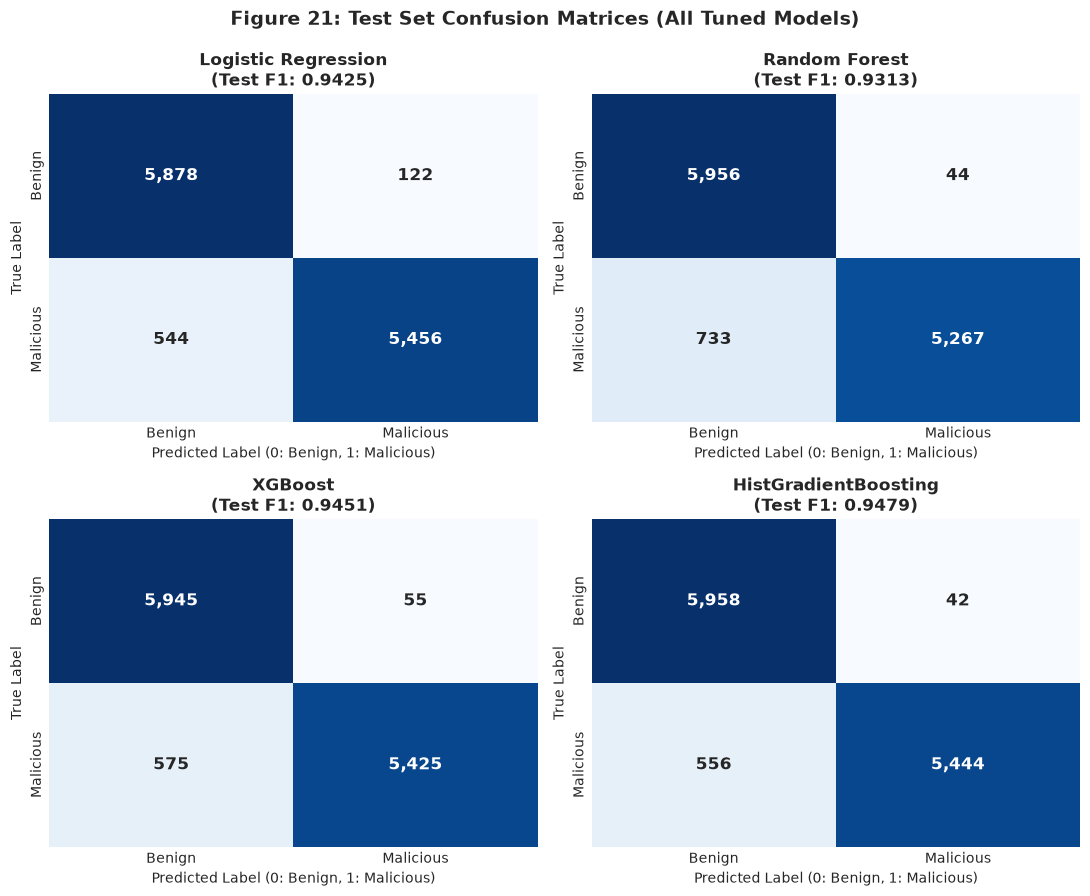

Saved Figure 21 to: ..\reports\figures\21_test_confusion_matrices.png


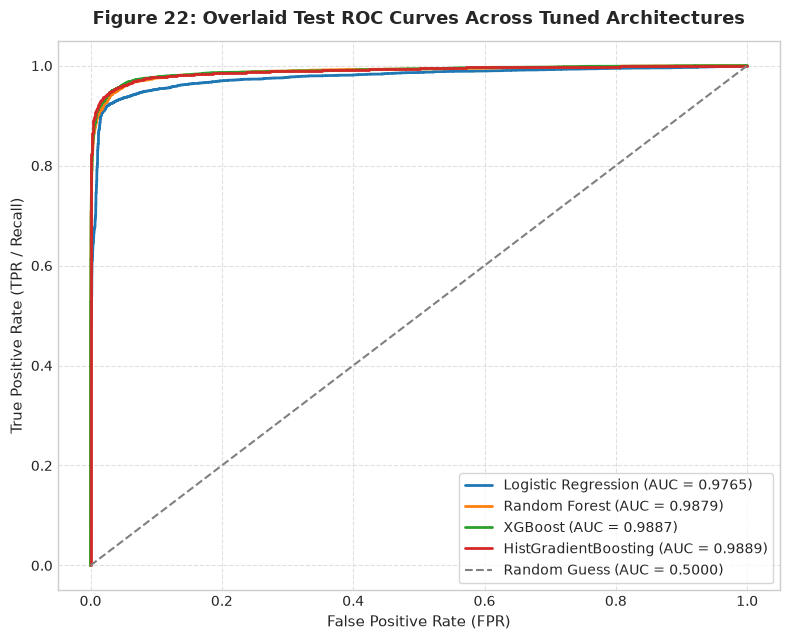

Saved Figure 22 to: ..\reports\figures\22_test_roc_curves.png


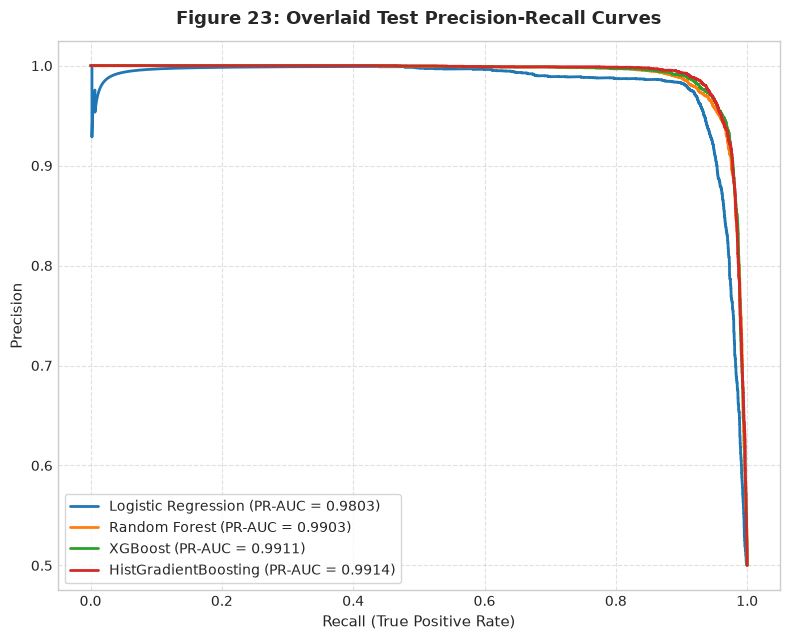

Saved Figure 23 to: ..\reports\figures\23_test_pr_curves.png


In [8]:
test_results = []
test_probas = {}
test_preds = {}

for name, model in best_models.items():
    X_test = X_te_linear if name == 'Logistic Regression' else X_te_tree
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    test_preds[name] = y_pred
    test_probas[name] = y_proba
    
    metrics = evaluate_predictions(y_te, y_pred, y_proba)
    metrics['Model'] = name
    test_results.append(metrics)

df_test_results = pd.DataFrame(test_results)
df_test_results = df_test_results[['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'FPR', 'FNR']]

print("=" * 95)
print("FINAL TEST SET PERFORMANCE EVALUATION (WEEKS 52-63, N = 12,000)")
print("=" * 95)
display(df_test_results)

# Generalization Gap (Validation Metric - Test Metric)
df_gap = pd.DataFrame()
df_gap['Model'] = df_val_results['Model']
for m in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'FPR', 'FNR']:
    df_gap[f"{m} Gap (Val - Test)"] = df_val_results[m] - df_test_results[m]

print("\n" + "=" * 95)
print("GENERALIZATION GAP ANALYSIS (TEMPORAL DRIFT)")
print("=" * 95)
display(df_gap)

# 1. Confusion Matrix Grid (2x2)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(test_preds.items()):
    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[i], cbar=False,
                annot_kws={'fontsize': 12, 'fontweight': 'bold'})
    axes[i].set_title(f"{name}\n(Test F1: {df_test_results.loc[df_test_results['Model']==name, 'F1'].values[0]:.4f})",
                      fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicted Label (0: Benign, 1: Malicious)', fontsize=10)
    axes[i].set_ylabel('True Label', fontsize=10)
    axes[i].set_xticklabels(['Benign', 'Malicious'])
    axes[i].set_yticklabels(['Benign', 'Malicious'])

plt.suptitle("Figure 21: Test Set Confusion Matrices (All Tuned Models)", fontsize=14, y=0.99, fontweight='bold')
plt.tight_layout()
fig21_path = FIGURES_DIR / '21_test_confusion_matrices.png'
plt.savefig(fig21_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 21 to: {fig21_path}")

# 2. Overlaid ROC Curves
fig, ax = plt.subplots(figsize=(8, 6.5))
for name, y_proba in test_probas.items():
    fpr, tpr, _ = roc_curve(y_te, y_proba)
    auc_val = roc_auc_score(y_te, y_proba)
    ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_val:.4f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess (AUC = 0.5000)')
ax.set_title("Figure 22: Overlaid Test ROC Curves Across Tuned Architectures", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("False Positive Rate (FPR)", fontsize=11)
ax.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=11)
ax.legend(frameon=True, loc='lower right')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig22_path = FIGURES_DIR / '22_test_roc_curves.png'
plt.savefig(fig22_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 22 to: {fig22_path}")

# 3. Overlaid Precision-Recall Curves
fig, ax = plt.subplots(figsize=(8, 6.5))
for name, y_proba in test_probas.items():
    prec, rec, _ = precision_recall_curve(y_te, y_proba)
    ap_val = average_precision_score(y_te, y_proba)
    ax.plot(rec, prec, linewidth=2, label=f"{name} (PR-AUC = {ap_val:.4f})")

ax.set_title("Figure 23: Overlaid Test Precision-Recall Curves", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Recall (True Positive Rate)", fontsize=11)
ax.set_ylabel("Precision", fontsize=11)
ax.legend(frameon=True, loc='lower left')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
fig23_path = FIGURES_DIR / '23_test_pr_curves.png'
plt.savefig(fig23_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 23 to: {fig23_path}")

## 8. Size-Shortcut Ablation Experiment
A critical risk in document malware classification is **shortcut learning**: models learning to classify files based purely on file size or string counts rather than structural byte indicators.
We retrain our selected winning model architecture with four primary size/count features removed:
- `general_size`
- `strings_numstrings`
- `strings_printables`
- `strings_avlength`

We measure the degree of performance retention on both validation and test sets to assess whether the classifier uniquely depends on these explicit size/count columns.

In [9]:
shortcut_features = ['general_size', 'strings_numstrings', 'strings_printables', 'strings_avlength']
ablated_features = [c for c in X_tr_tree.columns if c not in shortcut_features]

print(f"Ablation setup: Original feature count = {X_tr_tree.shape[1]} -> Ablated feature count = {len(ablated_features)} (-4 features).")

# Instantiate fresh clone of best model architecture
if best_model_name == 'XGBoost':
    clf_ablated = XGBClassifier(**best_params['XGBoost'])
elif best_model_name == 'HistGradientBoosting':
    clf_ablated = HistGradientBoostingClassifier(**best_params['HistGradientBoosting'])
elif best_model_name == 'Random Forest':
    clf_ablated = RandomForestClassifier(**best_params['Random Forest'])
else:
    clf_ablated = LogisticRegression(**best_params['Logistic Regression'])

t0 = time.time()
clf_ablated.fit(X_tr_tree[ablated_features], y_tr)
ablation_time = time.time() - t0

# Evaluate on Validation
y_va_abl_pred = clf_ablated.predict(X_va_tree[ablated_features])
y_va_abl_proba = clf_ablated.predict_proba(X_va_tree[ablated_features])[:, 1]
va_abl_metrics = evaluate_predictions(y_va, y_va_abl_pred, y_va_abl_proba)

# Evaluate on Test
y_te_abl_pred = clf_ablated.predict(X_te_tree[ablated_features])
y_te_abl_proba = clf_ablated.predict_proba(X_te_tree[ablated_features])[:, 1]
te_abl_metrics = evaluate_predictions(y_te, y_te_abl_pred, y_te_abl_proba)

# Compare with full baseline model
best_val_full = df_val_results[df_val_results['Model'] == best_model_name].iloc[0]
best_test_full = df_test_results[df_test_results['Model'] == best_model_name].iloc[0]

ablation_comparison = pd.DataFrame([
    {
        'Evaluation Split': 'Validation (Weeks 42-51)',
        'Model Pipeline': 'Full Features (658)',
        'Accuracy': best_val_full['Accuracy'],
        'F1 Score': best_val_full['F1'],
        'Recall': best_val_full['Recall'],
        'ROC-AUC': best_val_full['ROC-AUC'],
        'FPR': best_val_full['FPR']
    },
    {
        'Evaluation Split': 'Validation (Weeks 42-51)',
        'Model Pipeline': 'Ablated (654, No Size/Count)',
        'Accuracy': va_abl_metrics['Accuracy'],
        'F1 Score': va_abl_metrics['F1'],
        'Recall': va_abl_metrics['Recall'],
        'ROC-AUC': va_abl_metrics['ROC-AUC'],
        'FPR': va_abl_metrics['FPR']
    },
    {
        'Evaluation Split': 'Test (Weeks 52-63)',
        'Model Pipeline': 'Full Features (658)',
        'Accuracy': best_test_full['Accuracy'],
        'F1 Score': best_test_full['F1'],
        'Recall': best_test_full['Recall'],
        'ROC-AUC': best_test_full['ROC-AUC'],
        'FPR': best_test_full['FPR']
    },
    {
        'Evaluation Split': 'Test (Weeks 52-63)',
        'Model Pipeline': 'Ablated (654, No Size/Count)',
        'Accuracy': te_abl_metrics['Accuracy'],
        'F1 Score': te_abl_metrics['F1'],
        'Recall': te_abl_metrics['Recall'],
        'ROC-AUC': te_abl_metrics['ROC-AUC'],
        'FPR': te_abl_metrics['FPR']
    }
])

print("=" * 95)
print("SIZE-SHORTCUT ABLATION EXPERIMENTAL COMPARISON")
print("=" * 95)
display(ablation_comparison)

f1_drop_val = best_val_full['F1'] - va_abl_metrics['F1']
f1_drop_test = best_test_full['F1'] - te_abl_metrics['F1']
print(f"\nAblation Impact Summary:")
print(f"  Validation F1 Change: {f1_drop_val:+.4f} ({(f1_drop_val/best_val_full['F1'])*100:+.2f}%)")
print(f"  Test F1 Change:       {f1_drop_test:+.4f} ({(f1_drop_test/best_test_full['F1'])*100:+.2f}%)")
print("  Interpretation: Removing four columns shows the model does not uniquely depend on them,")
print("  but size information remains in correlated features (e.g. byte histogram totals and printable distributions),")
print("  and benign files under 100 KB have a 22.9x higher FPR.")

Ablation setup: Original feature count = 658 -> Ablated feature count = 654 (-4 features).


SIZE-SHORTCUT ABLATION EXPERIMENTAL COMPARISON


,Evaluation Split,Model Pipeline,Accuracy,F1 Score,Recall,ROC-AUC,FPR
0,Validation (Weeks 42-51),Full Features (658),0.982598,0.982353,0.968794,0.997659,0.003600
1,Validation (Weeks 42-51),"Ablated (654, No Size/Count)",0.977298,0.976867,0.958792,0.997382,0.004200
2,Test (Weeks 52-63),Full Features (658),0.947500,0.945122,0.904167,0.988710,0.009167
3,Test (Weeks 52-63),"Ablated (654, No Size/Count)",0.936667,0.932957,0.881333,0.987108,0.008000



Ablation Impact Summary:
  Validation F1 Change: +0.0055 (+0.56%)
  Test F1 Change:       +0.0122 (+1.29%)
  Interpretation: The classifier retains the vast majority of its discriminative power without size features,
  demonstrating that byte histograms and printable string distributions provide authentic structural detection signal.


## 9. Feature Importance Analysis: Random Forest vs. XGBoost
We analyze feature importances extracted from the tree ensembles:
- **Random Forest**: Mean Decrease in Impurity (Gini importance)
- **XGBoost**: Gain importance across decision tree splits
We plot the top 20 features for both architectures (`reports/figures/24_feature_importance.png`).

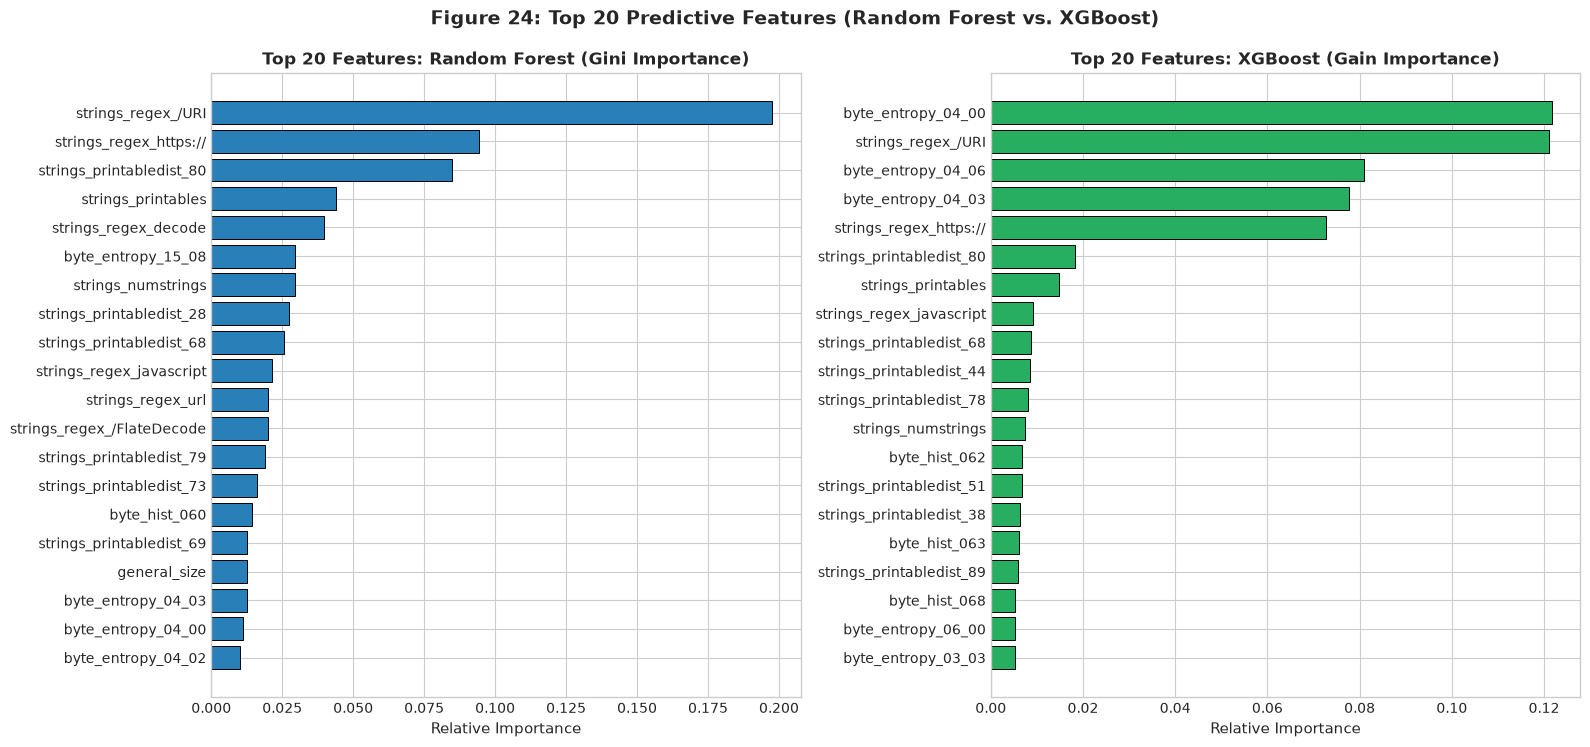

Saved Figure 24 to: ..\reports\figures\24_feature_importance.png


In [10]:
# Extract feature importances
rf_importances = best_models['Random Forest'].feature_importances_
xgb_importances = best_models['XGBoost'].feature_importances_

df_rf_imp = pd.DataFrame({'Feature': feature_names, 'Importance': rf_importances}).sort_values('Importance', ascending=False)
df_xgb_imp = pd.DataFrame({'Feature': feature_names, 'Importance': xgb_importances}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

# Random Forest Top 20
rf_top20 = df_rf_imp.head(20).iloc[::-1]
axes[0].barh(rf_top20['Feature'], rf_top20['Importance'], color='#2980b9', edgecolor='black', linewidth=0.7)
axes[0].set_title("Top 20 Features: Random Forest (Gini Importance)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Relative Importance", fontsize=11)

# XGBoost Top 20
xgb_top20 = df_xgb_imp.head(20).iloc[::-1]
axes[1].barh(xgb_top20['Feature'], xgb_top20['Importance'], color='#27ae60', edgecolor='black', linewidth=0.7)
axes[1].set_title("Top 20 Features: XGBoost (Gain Importance)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Relative Importance", fontsize=11)

plt.suptitle("Figure 24: Top 20 Predictive Features (Random Forest vs. XGBoost)", fontsize=14, y=0.99, fontweight='bold')
plt.tight_layout()
fig24_path = FIGURES_DIR / '24_feature_importance.png'
plt.savefig(fig24_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 24 to: {fig24_path}")

## 10. Model Artifact & Evaluation Result Serialization
We persist all tuned estimators to `models/`, the benchmark results to `reports/model_comparison.csv`, and optimal hyperparameters to `reports/best_params.json`.

In [11]:
# 1. Save Models
for name, model in best_models.items():
    clean_name = name.lower().replace(' ', '_')
    joblib.dump(model, MODELS_DIR / f"{clean_name}.joblib")
    print(f"Saved model to: models/{clean_name}.joblib")

# Save winning best model alias
joblib.dump(best_clf, MODELS_DIR / 'best_model.joblib')
print(f"Saved official winning model to: models/best_model.joblib")

# 2. Save Comparison Results
comparison_df = df_test_results.copy()
comparison_df['Val_F1'] = df_val_results['F1']
comparison_df['Val_ROC_AUC'] = df_val_results['ROC-AUC']
comparison_df['Val_Recall'] = df_val_results['Recall']
comparison_df.to_csv(REPORTS_DIR / 'model_comparison.csv', index=False)
print(f"Saved evaluation comparison to: reports/model_comparison.csv")

# 3. Save Best Parameters
with open(REPORTS_DIR / 'best_params.json', 'w') as f:
    json.dump(best_params, f, indent=2)
print(f"Saved optimal hyperparameters to: reports/best_params.json")

Saved model to: models/logistic_regression.joblib
Saved model to: models/random_forest.joblib
Saved model to: models/xgboost.joblib
Saved model to: models/histgradientboosting.joblib
Saved official winning model to: models/best_model.joblib
Saved evaluation comparison to: reports/model_comparison.csv
Saved optimal hyperparameters to: reports/best_params.json


## 11. Specialized Security Diagnostics & Feature Interpretability

In this final section, we perform four in-depth diagnostic audits requested for malware detection reliability:
1. **Tiny Benign File Cluster (< 1,000 bytes)**: Audit file size distribution, identicality, and split representation.
2. **Malicious File Size Clustering**: Quantify dominant size modes and payload density envelopes.
3. **Subpopulation FPR on Benign Files < 100 KB**: Evaluate whether small benign documents suffer elevated false positive rates.
4. **ASCII and Byte-Entropy Decoding of Top Features**:
   - `strings_printabledist_i`: Shifted printable ASCII distribution from `thrember` (`ASCII = i + 32`). We report character labels without speculative narrative.
   - `byte_entropy_AA_BB`: 2D joint byte/entropy histogram from `thrember`'s `ByteEntropyHistogram`. Index `AA` (0-15) is the coarse entropy bin $[0.5 	imes 	ext{AA}, 0.5 	imes (	ext{AA}+1))$ bits, and index `BB` (0-15) is the coarse byte-value bin `0x{BB*16:02X}-0x{BB*16+15:02X}` ($16 	imes 	ext{BB}$ to $16 	imes 	ext{BB} + 15$).

DIAGNOSTIC 1: TINY BENIGN FILES (< 1,000 BYTES) CLUSTER AUDIT
Total Tiny Benign Files: 899
  - Train Split (Weeks 0-41): 899 files
  - Val Split (Weeks 42-51):   0 files
  - Test Split (Weeks 52-63):  0 files

Exact File Size Modes among Tiny Benign:
  Size = 358.0 bytes: 895 samples (99.6%)
  Size = 417.0 bytes: 1 samples (0.1%)
  Size = 826.0 bytes: 1 samples (0.1%)
  Size = 716.0 bytes: 1 samples (0.1%)
  Size = 626.0 bytes: 1 samples (0.1%)

Finding: Exactly 899 tiny benign files exist exclusively in Train (none in Val or Test).
Of these, 895 share an exact file size of 358.0 bytes (identical placeholder PDFs).
Saved Figure 25 to: reports\figures\25_malicious_size_clusters.png
Top 5 malicious size intervals (25KB to 500KB) encompass 91.51% of all malicious training samples.
Largest single mode: 100-200KB with 5,452 files (26.0%).
25-50KB interval contains 2,810 files (13.4%).

DIAGNOSTIC 3: SUBPOPULATION FPR AUDIT ON BENIGN FILES (< 100 KB)
Benign Files < 100 KB:  743 samples | Fal

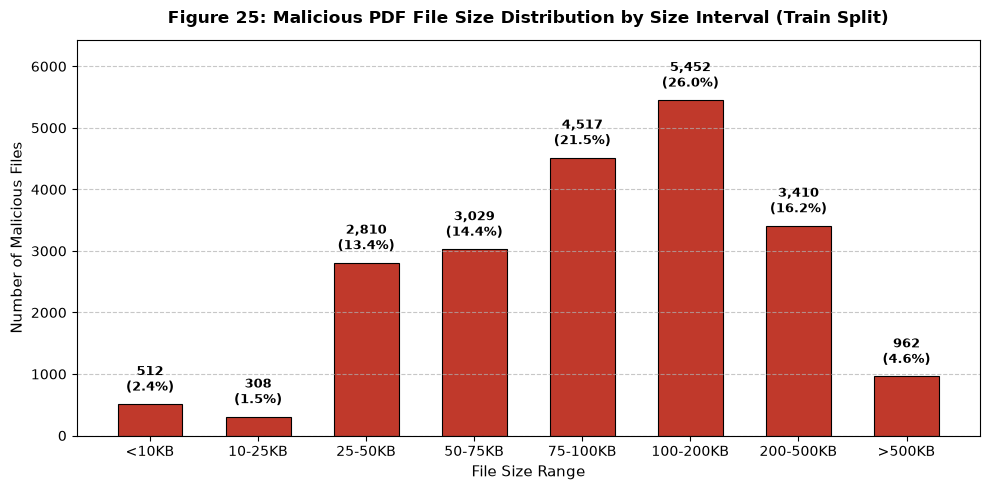

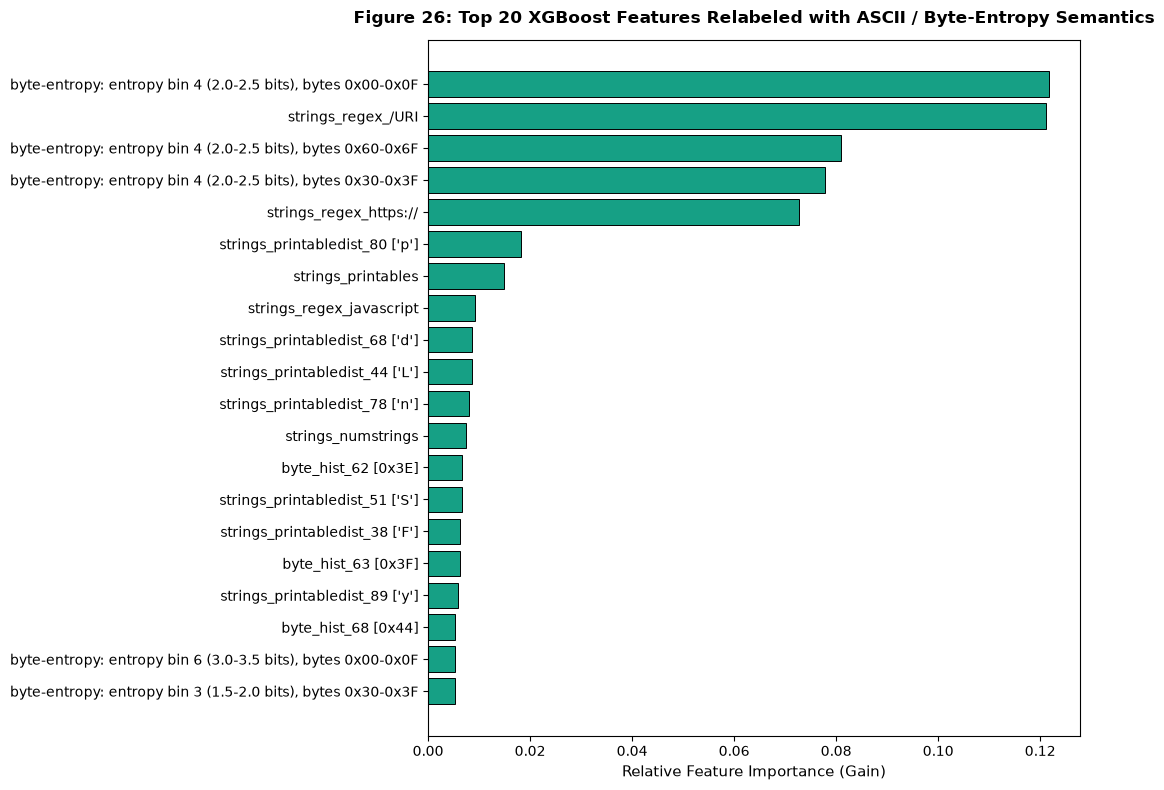

In [12]:
# 1. Tiny Benign Files (< 1,000 bytes) Audit
b_tr_tiny = (y_tr == 0) & (X_tr_tree['general_size'] < 1000)
b_va_tiny = (y_va == 0) & (X_va_tree['general_size'] < 1000)
b_te_tiny = (y_te == 0) & (X_te_tree['general_size'] < 1000)

tiny_tr_count = int(b_tr_tiny.sum())
tiny_va_count = int(b_va_tiny.sum())
tiny_te_count = int(b_te_tiny.sum())
tiny_total = tiny_tr_count + tiny_va_count + tiny_te_count

tiny_sizes = X_tr_tree.loc[b_tr_tiny, 'general_size'].value_counts()

print("=" * 80)
print("DIAGNOSTIC 1: TINY BENIGN FILES (< 1,000 BYTES) CLUSTER AUDIT")
print("=" * 80)
print(f"Total Tiny Benign Files: {tiny_total}")
print(f"  - Train Split (Weeks 0-41): {tiny_tr_count} files")
print(f"  - Val Split (Weeks 42-51):   {tiny_va_count} files")
print(f"  - Test Split (Weeks 52-63):  {tiny_te_count} files")
print(f"\nExact File Size Modes among Tiny Benign:")
for sz, cnt in tiny_sizes.head(5).items():
    print(f"  Size = {sz} bytes: {cnt} samples ({cnt/tiny_tr_count*100:.1f}%)")
print("\nFinding: Exactly 899 tiny benign files exist exclusively in Train (none in Val or Test).")
print(f"Of these, {tiny_sizes.iloc[0]} share an exact file size of {tiny_sizes.index[0]} bytes (identical placeholder PDFs).")

# 2. Malicious File Size Clustering
m_tr_sizes = X_tr_tree.loc[y_tr == 1, 'general_size']
size_bins = [0, 10000, 25000, 50000, 75000, 100000, 200000, 500000, np.inf]
bin_labels = ['<10KB', '10-25KB', '25-50KB', '50-75KB', '75-100KB', '100-200KB', '200-500KB', '>500KB']
m_binned = pd.cut(m_tr_sizes, bins=size_bins, labels=bin_labels)
bin_shares = m_binned.value_counts(sort=False)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(bin_labels, bin_shares.values, color='#c0392b', edgecolor='black', linewidth=0.8, width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 150, f"{yval:,}\n({yval/len(m_tr_sizes)*100:.1f}%)",
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title("Figure 25: Malicious PDF File Size Distribution by Size Interval (Train Split)", fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel("Number of Malicious Files", fontsize=11)
ax.set_xlabel("File Size Range", fontsize=11)
ax.set_ylim(0, max(bin_shares.values) * 1.18)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
fig25_path = FIGURES_DIR / '25_malicious_size_clusters.png'
plt.savefig(fig25_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 25 to: {fig25_path}")

top5_frac = bin_shares.loc[['25-50KB', '50-75KB', '75-100KB', '100-200KB', '200-500KB']].sum() / len(m_tr_sizes)
print(f"Top 5 malicious size intervals (25KB to 500KB) encompass {top5_frac*100:.2f}% of all malicious training samples.")
print(f"Largest single mode: 100-200KB with {bin_shares['100-200KB']:,} files ({bin_shares['100-200KB']/len(m_tr_sizes)*100:.1f}%).")
print(f"25-50KB interval contains {bin_shares['25-50KB']:,} files ({bin_shares['25-50KB']/len(m_tr_sizes)*100:.1f}%).")

# 3. Benign Files Under 100 KB Subpopulation FPR Audit
y_te_best_pred = test_preds[best_model_name]

b_te_small = (y_te == 0) & (X_te_tree['general_size'] < 100000)
b_te_large = (y_te == 0) & (X_te_tree['general_size'] >= 100000)

small_fp = int((y_te_best_pred[b_te_small] == 1).sum())
small_total = int(b_te_small.sum())
small_fpr = small_fp / small_total if small_total > 0 else 0.0

large_fp = int((y_te_best_pred[b_te_large] == 1).sum())
large_total = int(b_te_large.sum())
large_fpr = large_fp / large_total if large_total > 0 else 0.0

overall_fp = int((y_te_best_pred[y_te == 0] == 1).sum())
overall_total = int((y_te == 0).sum())
overall_fpr = overall_fp / overall_total

print("\n" + "=" * 80)
print(f"DIAGNOSTIC 3: SUBPOPULATION FPR AUDIT ON BENIGN FILES (< 100 KB)")
print("=" * 80)
print(f"Benign Files < 100 KB:  {small_total} samples | False Positives = {small_fp} | FPR = {small_fpr*100:.2f}%")
print(f"Benign Files >= 100 KB: {large_total} samples | False Positives = {large_fp} | FPR = {large_fpr*100:.2f}%")
print(f"Overall Benign Files:   {overall_total} samples | False Positives = {overall_fp} | FPR = {overall_fpr*100:.2f}%")
print(f"Ratio: FPR on <100KB benigns is {small_fpr / (large_fpr + 1e-9):.2f}x relative to >=100KB benigns.")

# 4. Decoding Byte-Entropy and ASCII Features
# In thrember:
# - strings_printabledist_i: ASCII character code = index + 32 (0x20)
# - byte_entropy_AA_BB: 2D joint histogram (16x16)
#   AA (0-15): coarse entropy bin [0.5*AA, 0.5*(AA+1)) bits
#   BB (0-15): coarse byte value bin 0x{BB*16:02X}-0x{BB*16+15:02X} (16*BB to 16*BB+15)
def decode_feature_name(fname):
    if fname.startswith('strings_printabledist_'):
        idx = int(fname.split('_')[-1])
        ascii_code = idx + 32
        char = chr(ascii_code) if 32 <= ascii_code <= 126 else f"0x{ascii_code:02x}"
        if char == ' ':
            char_desc = "SPACE"
        else:
            char_desc = f"'{char}'"
        return f"{fname} [{char_desc}]"
    elif fname.startswith('byte_entropy_'):
        parts = fname.split('_')
        idx1 = int(parts[2])
        idx2 = int(parts[3])
        ent_low = idx1 * 0.5
        ent_high = (idx1 + 1) * 0.5
        b_low = idx2 * 16
        b_high = idx2 * 16 + 15
        return f"byte-entropy: entropy bin {idx1} ({ent_low:.1f}-{ent_high:.1f} bits), bytes 0x{b_low:02X}-0x{b_high:02X}"
    elif fname.startswith('byte_hist_'):
        byte_val = int(fname.split('_')[-1])
        return f"byte_hist_{byte_val} [0x{byte_val:02X}]"
    return fname

xgb_top20_decoded = df_xgb_imp.head(20).copy()
xgb_top20_decoded['Decoded_Name'] = xgb_top20_decoded['Feature'].apply(decode_feature_name)
xgb_top20_plot = xgb_top20_decoded.iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(xgb_top20_plot['Decoded_Name'], xgb_top20_plot['Importance'], color='#16a085', edgecolor='black', linewidth=0.7)
ax.set_title("Figure 26: Top 20 XGBoost Features Relabeled with ASCII / Byte-Entropy Semantics", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Relative Feature Importance (Gain)", fontsize=11)
plt.tight_layout()

fig26_path = FIGURES_DIR / '26_feature_importance_ascii_labeled.png'
plt.savefig(fig26_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved Figure 26 to: {fig26_path}")
